# 03 · Feature engineering and content embeddings

The original project's content embedding used **only the text** of each track (name + artist +
album, via TF-IDF or SBERT). That ignores the strongest content signal in the dataset: Spotify's
audio analysis. Two songs called *Hold On* by different artists are close in text space and may
sound nothing alike.

This notebook builds three feature blocks and combines them:

1. **Audio** - engineered from the nine audio features plus key, mode and duration
2. **Genre** - a learned 24-dimensional genre embedding
3. **Text** - TF-IDF over title, album and artist tokens (the original signal, now a minor part)

Code: `src/features/`.

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src import config

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
FIG = config.FIGURES
FIG.mkdir(parents=True, exist_ok=True)
from src.data.load import load_catalog
from src.features.audio_features import AudioFeatureEngineer, fold_tempo, circle_of_fifths, weighted, FEATURE_WEIGHTS, SKEWED
tracks = load_catalog()
print(tracks.shape)

(22800, 25)


## 1. Audio block

### Tempo: fold octave errors
Fold every tempo into [70, 140) BPM and use log2, so 87 and 174 BPM become the same *feel* and
a 10 BPM gap at 80 counts more than at 160.

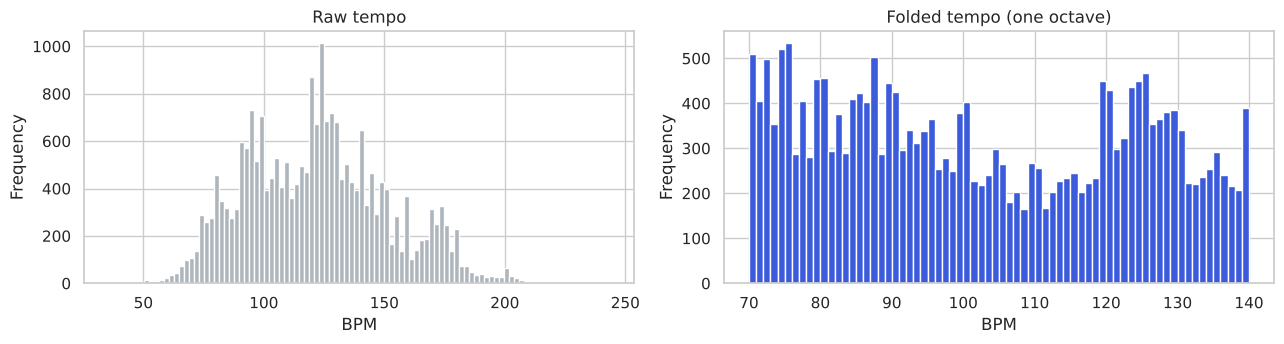

tracks moved by folding: 27.3%


In [2]:
folded = fold_tempo(tracks.tempo)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
tracks.tempo.plot.hist(bins=100, ax=axes[0], color="#adb5bd"); axes[0].set(title="Raw tempo", xlabel="BPM")
folded.plot.hist(bins=70, ax=axes[1], color="#3b5bdb"); axes[1].set(title="Folded tempo (one octave)", xlabel="BPM")
plt.tight_layout(); plt.savefig(FIG / "03_tempo_fold.png"); plt.show()
print(f"tracks moved by folding: {(folded != tracks.tempo).mean():.1%}")

### Key: circle of fifths instead of 0-11
Key is stored as a pitch class 0-11, so C (0) and B (11) look maximally far apart although they
are neighbours. Musically, keys that mix well are neighbours on the **circle of fifths**, and a minor
key shares every note with its relative major (A minor = C major). Each key is mapped to that circle
and encoded as sin/cos, which is what DJs' "Camelot wheel" does.

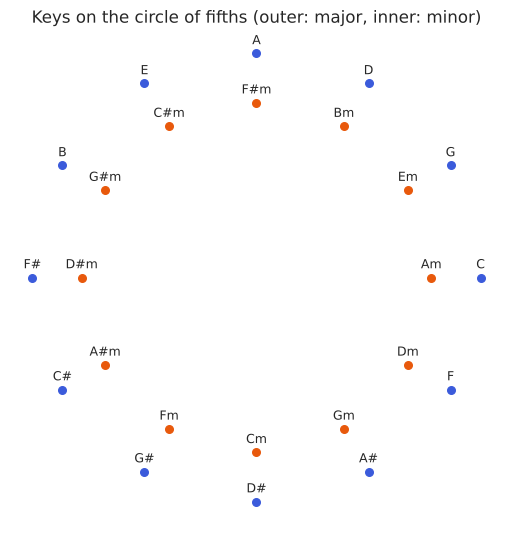

In [3]:
names = ["C","C#","D","D#","E","F","F#","G","G#","A","A#","B"]
demo = pd.DataFrame([(k, m) for m in (1, 0) for k in range(12)], columns=["key", "mode"])
s, c = circle_of_fifths(demo.key.values, demo["mode"].values)
demo["name"] = [names[k] + ("" if m else "m") for k, m in zip(demo.key, demo["mode"])]
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for (x, y, n, m) in zip(c, s, demo.name, demo["mode"]):
    r = 1 if m else 0.78
    ax.scatter(x * r, y * r, color="#3b5bdb" if m else "#e8590c", s=30)
    ax.annotate(n, (x * r, y * r), ha="center", va="center", xytext=(0, 9), textcoords="offset points", fontsize=9)
ax.set_aspect("equal"); ax.axis("off"); ax.set_title("Keys on the circle of fifths (outer: major, inner: minor)")
plt.tight_layout(); plt.savefig(FIG / "03_circle_of_fifths.png"); plt.show()

### Skewed features: quantile transform
`speechiness`, `acousticness`, `instrumentalness` and `liveness` are mapped through their own
empirical distribution onto a normal shape, so a step in the crowded low range counts as much as
a step in the sparse high range.

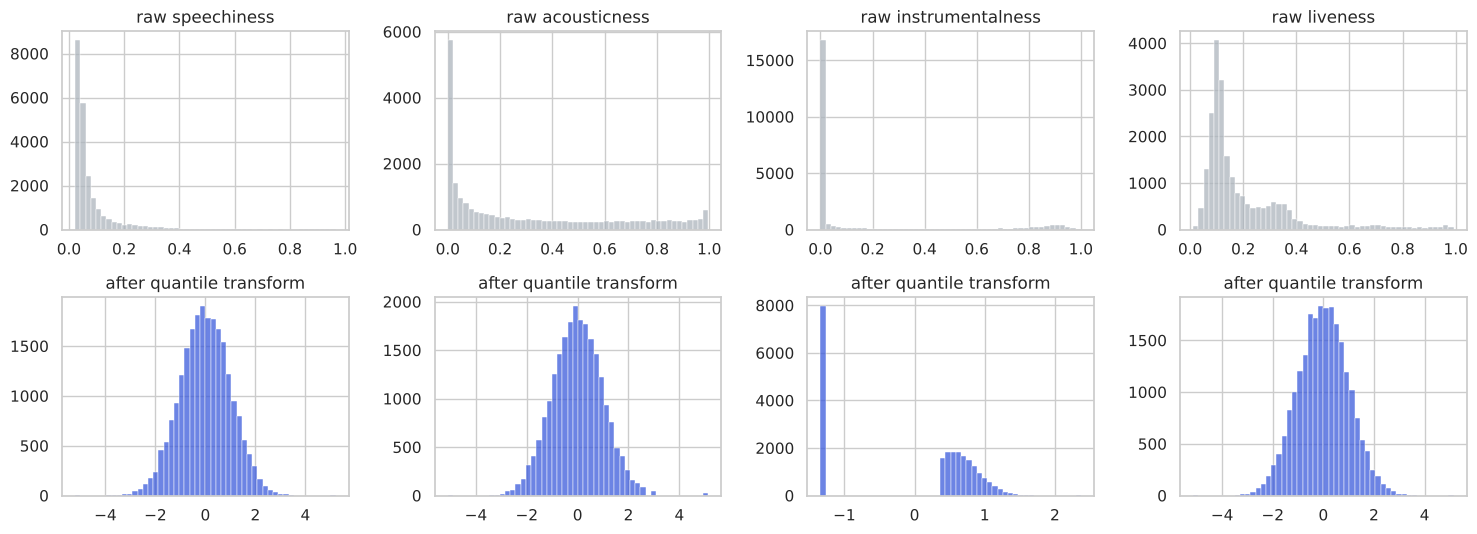

In [4]:
fe = AudioFeatureEngineer()
X = fe.fit_transform(tracks)
fig, axes = plt.subplots(2, 4, figsize=(15, 5.5))
for j, f in enumerate(SKEWED):
    sns.histplot(tracks[f], bins=50, ax=axes[0, j], color="#adb5bd", edgecolor=None); axes[0, j].set(title=f"raw {f}", xlabel="", ylabel="")
    sns.histplot(X[f"q_{f}"], bins=50, ax=axes[1, j], color="#3b5bdb", edgecolor=None); axes[1, j].set(title="after quantile transform", xlabel="", ylabel="")
plt.tight_layout(); plt.savefig(FIG / "03_quantile.png"); plt.show()

The spikes left after the transform are ties (many tracks share instrumentalness ≈ 0); a
quantile transform cannot spread identical values, and it does not need to.

### Derived features and weights
* `groove` = danceability × energy: a track can be danceable but laid back, or energetic but
  undanceable; the product picks out tracks that are both.
* `log_duration`: a 10-minute track and a 3-minute track differ in kind, two 3-4 minute tracks do not.

Then every column is standardised and multiplied by a weight. Weights encode the EDA:
energy, acousticness and valence matter most for how a track feels; loudness is mostly a
duplicate of energy, so it is turned down; key matters only a little.

In [5]:
audio = weighted(X)
pd.DataFrame({"weight": FEATURE_WEIGHTS}).T

,danceability,energy,valence,loudness,tempo_feel,groove,log_duration,key_sin,key_cos,major,q_speechiness,q_acousticness,q_instrumentalness,q_liveness
weight,1.0,1.2,1.0,0.6,0.7,0.6,0.3,0.25,0.25,0.3,0.7,1.1,0.9,0.3


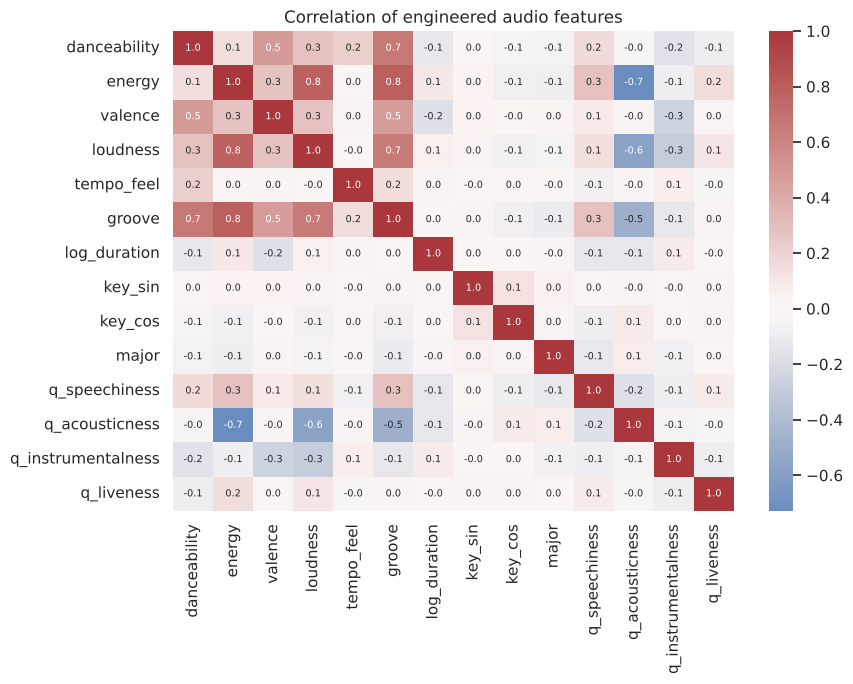

In [6]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(X.corr(), cmap="vlag", center=0, ax=ax, annot=True, fmt=".1f", annot_kws={"size": 7})
ax.set_title("Correlation of engineered audio features")
plt.tight_layout(); plt.savefig(FIG / "03_engineered_corr.png"); plt.show()

## 2. Genre block: a learned genre map

114 one-hot genres would say *punk* and *punk-rock* are as different as *punk* and *opera*. We
build a genre-to-genre similarity from two sources and embed it:

* **co-listing** - PPMI (positive pointwise mutual information) of two genres labelling the same track;
* **sound** - cosine similarity between the genres' average engineered audio vectors.

The blended similarity matrix is factorised with truncated SVD into a 24-dimensional vector per
genre; a track's genre vector is the average of its genres' vectors.

In [7]:
from src.features.genre_embeddings import GenreEmbedder
ge = GenreEmbedder(dim=24).fit(tracks.genres, audio)
show = ["rock", "jazz", "hip-hop", "classical", "techno", "k-pop", "metal", "folk"]
pd.DataFrame({g: [f"{n} ({v:.2f})" for n, v in ge.nearest(g, 5).items()] for g in show}).T.rename(columns=lambda i: f"#{i + 1}")

,#1,#2,#3,#4,#5
rock,alt-rock (0.52),alternative (0.51),power-pop (0.44),garage (0.41),punk-rock (0.41)
jazz,piano (0.46),romance (0.46),singer-songwriter (0.46),songwriter (0.46),folk (0.46)
hip-hop,latino (0.55),reggaeton (0.55),reggae (0.53),latin (0.53),pop (0.51)
classical,piano (0.60),ambient (0.60),new-age (0.52),romance (0.49),disney (0.46)
techno,minimal-techno (0.74),electronic (0.55),deep-house (0.49),club (0.49),trance (0.48)
k-pop,dance (0.47),spanish (0.44),latin (0.44),party (0.44),j-dance (0.43)
metal,grunge (0.68),metalcore (0.63),hard-rock (0.62),heavy-metal (0.59),alternative (0.58)
folk,singer-songwriter (0.58),songwriter (0.58),acoustic (0.54),ambient (0.53),indian (0.52)


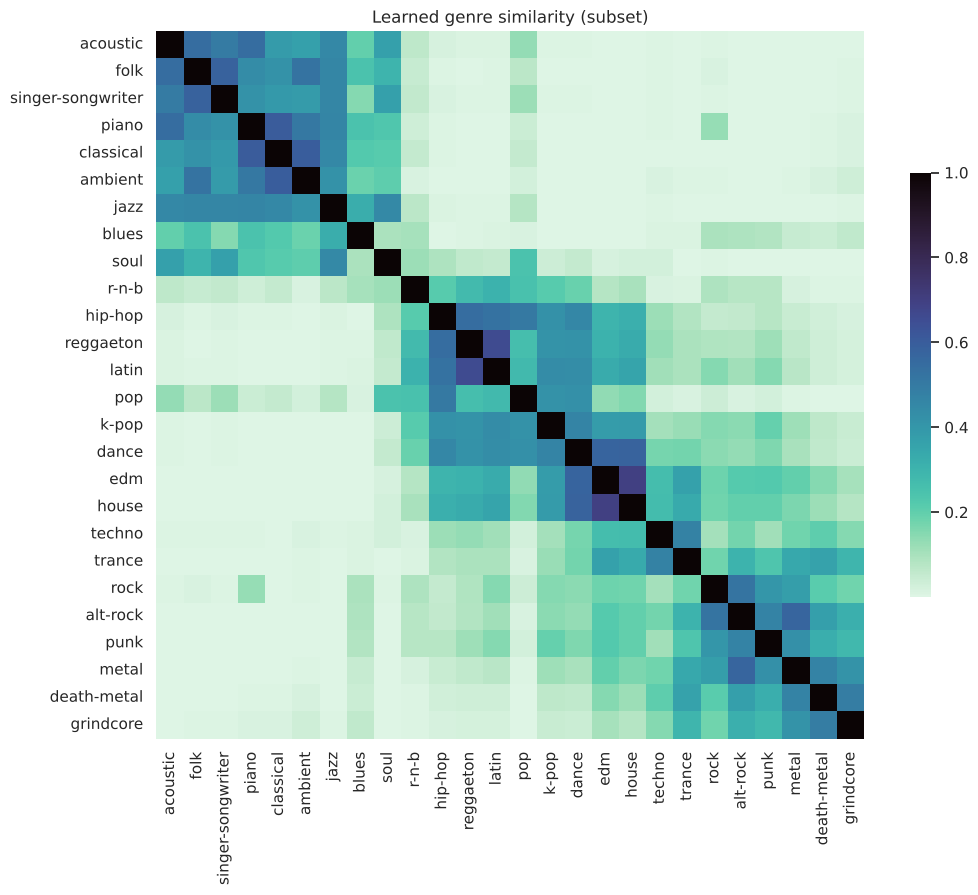

In [8]:
sub = ["acoustic", "folk", "singer-songwriter", "piano", "classical", "ambient", "jazz", "blues", "soul",
       "r-n-b", "hip-hop", "reggaeton", "latin", "pop", "k-pop", "dance", "edm", "house", "techno",
       "trance", "rock", "alt-rock", "punk", "metal", "death-metal", "grindcore"]
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(ge.similarity_.loc[sub, sub], cmap="mako_r", ax=ax, square=True, cbar_kws={"shrink": .6})
ax.set_title("Learned genre similarity (subset)")
plt.tight_layout(); plt.savefig(FIG / "03_genre_similarity.png"); plt.show()

Blocks of related scenes appear on the diagonal (extreme metal, electronic dance, quiet acoustic, Latin/urban) without any of them being hand-labelled.

## 3. Text block

In [9]:
from src.features.text_features import TextEmbedder, metadata_text
print(metadata_text(tracks.head(3)).tolist())
text = TextEmbedder(dim=64).fit_transform(tracks)
genre_vecs = ge.track_vectors()
print("audio", audio.shape, " genre", genre_vecs.shape, " text", text.shape)

['unholy (feat. kim petras) unholy (feat. kim petras) artist_sam_smith artist_kim_petras', 'quevedo: bzrp music sessions, vol. 52 quevedo: bzrp music sessions, vol. 52 artist_bizarrap artist_quevedo', 'la bachata la bachata artist_manuel_turizo']


audio (22800, 14)  genre (22800, 24)  text (22800, 64)


Artists become single tokens (`artist_daft_punk`), so two tracks by the same artist share a
feature even when their titles share nothing.

## 4. Combine and sanity-check

Each block is L2-normalised per track, scaled by a block weight and concatenated, then normalised
again so a dot product is a cosine similarity. The block weights are tuned on validation
playlists in notebook 05; here we use defaults and compare neighbours from the **text-only**
embedding (the original approach) with the **combined** one.

In [10]:
from src.features.content_embeddings import combine, DEFAULT_BLOCK_WEIGHTS
E = combine({"audio": audio, "genre": genre_vecs, "text": text}, DEFAULT_BLOCK_WEIGHTS)

def neighbours(emb, q, k=5):
    i = tracks.index[tracks.track_name.str.lower().str.startswith(q.lower())][0]
    from sklearn.preprocessing import normalize
    En = normalize(emb)
    s = En @ En[i]; s[i] = -1
    top = np.argsort(-s)[:k]
    return [f"{tracks.track_name[j][:30]} - {tracks.main_artist[j]} ({tracks.primary_genre[j]})" for j in top]

for q in ["Clair de Lune", "Smells Like Teen Spirit", "Hold On"]:
    i = tracks.index[tracks.track_name.str.lower().str.startswith(q.lower())][0]
    print(f"\n>>> {tracks.track_name[i]} - {tracks.main_artist[i]} ({tracks.primary_genre[i]})")
    display(pd.DataFrame({"text only (original)": neighbours(text, q), "audio + genre + text": neighbours(E, q)}))


>>> Clair de Lune, L. 32 - Claude Debussy (classical)


,text only (original),audio + genre + text
0,Rap de las Hormigas - Charly García (punk-rock),Fleurs de cerisier - Chloé Czans (piano)
1,Labios Carmin - Los Vaguens (rockabilly),Rodrigo: Concierto de Aranjuez - Joaquín Rodri...
2,De Remate - Pipe Calderón (reggaeton),Afterthought - Elliott Jacqués (classical)
3,Mr. Guantecillo - Hermanos Com - 31 Minutos (ska),Stargaze - Sarah Watson (classical)
4,Sur l'océan couleur de fer - Alcest (black-metal),Hallelujah - Brian Crain (new-age)



>>> Smells Like Teen Spirit - Nirvana (rock)


,text only (original),audio + genre + text
0,Norwegian Wood (This Bird Has - The Beatles (...,Blew - Nirvana (grunge)
1,Row Like A Boat - Beenie Man (j-dance),Come As You Are - Nirvana (rock)
2,Like a Rolling Stone - Bob Dylan (folk),You Spin Me Round (Like A Reco - Dope (industr...
3,Like a Stone - Audioslave (metal),Fuel - Metallica (metal)
4,I'm Like A Bird - Nelly Furtado (latin),Rock You Like a Hurricane - 20 - Scorpions (me...



>>> Hold On - Chord Overstreet (acoustic)


,text only (original),audio + genre + text
0,Hold On - Armin van Buuren (trance),Easy On My Eyes - Stephen Sanchez (songwriter)
1,Hold On - Netsky (drum-and-bass),Creep - Kina Grannis (acoustic)
2,Hold On (Instrumental Guitar) - Guus Dielissen...,Habits - Scott Bradlee's Postmodern Jukebox (j...
3,Hold On - Gojira (death-metal),Cloud 9 - Paravi (indie-pop)
4,Horns - Bryce Fox (alt-rock),猜不透 - Della (mandopop)


Text-only neighbours are driven by shared words in titles and albums. The combined embedding returns tracks that sound and sit in the same scene. Notebook 05 measures the difference on held-out playlists instead of eyeballing it.

In [11]:
from src import artifacts
artifacts.save_features(audio, X.columns, genre_vecs, text, E, ge.similarity_, DEFAULT_BLOCK_WEIGHTS)
print("saved", config.FEATURES.relative_to(config.PROJECT_ROOT))

saved data/processed/content_features.npz
